# 04 (enhanced ablation) — Behavioral/Time-Windowed Features vs. Baseline

Standalone experiment, on the `behavioral-time-windowed-features` branch. Tests whether the
12 new per-source-IP time-windowed behavioral columns in
`data/processed/behavioral/cicids2017_behavioral_labeled.parquet`
(`conn_count`/`uniq_dport_count`/`fail_ratio`/`repeat_ratio` × 1/3/5-minute windows) improve
Isolation Forest's and the Autoencoder's detection of the categories both were structurally
blind to on the original 80-feature set: **FTP-Patator, SSH-Patator, PortScan, Bot**
(near-0% recall in `reports/isolation_forest_val_metrics.csv` /
`reports/autoencoder_val_metrics.csv`).

Motivation: `repeat_ratio` was already shown (in the branch's earlier behavioral-feature
verification pass) to separate FTP-/SSH-Patator from BENIGN by a 5–16x median ratio, closing
a gap `fail_ratio` alone could not (Patator brute-forces complete the TCP handshake normally;
the failure is at the application layer, invisible to flow-level TCP flags).

**This notebook is read/append-only with respect to the existing pipeline**: it loads
`models/isolation_forest.pkl` and `models/autoencoder.pt` **read-only** for the before/after
baseline comparison, and never writes to `preprocess_pipeline.py`, `label_builder.py`,
`feature_extractor.py`, `data/processed/*` (top-level), `data/features/*`, or either baseline
model file. All new outputs are separately namespaced (`*_behavioral` / `enhanced_ablation_*`).

No LOAO in this notebook — zero-day evaluation is deliberately deferred until this val-set
result justifies the extra 10-fold-retrain cost (Isolation Forest + Autoencoder, per the
existing per-notebook LOAO convention).

## 1. Setup

In [1]:
# Same Intel OpenMP workaround as 03_autoencoder.ipynb -- Anaconda's numpy/scikit-learn and
# the pip torch wheel both bundle libiomp5md.dll on this machine; must be set before `import torch`.
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)

print("torch version:", torch.__version__, " | cuda available:", torch.cuda.is_available())


torch version: 2.12.1+cu130  | cuda available: True


In [2]:
# Repo root -- same convention as 01/03 (parent of notebooks/ when opened normally).
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PROCESSED_BEHAVIORAL_DIR = ROOT / "data" / "processed" / "behavioral"
DATA_FEATURES_DIR = ROOT / "data" / "features"   # baseline (80-feature) score/feature files, read-only here
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"

print("ROOT:", ROOT)


ROOT: E:\thesis


In [3]:
# Config. IF contamination pinned at 0.20 (the value 01_isolation_forest.ipynb tuned on the
# original 80-feature set) as the starting point for this experiment -- Section 7b re-checks
# with a diagnostic sweep whether the new features shift the optimum, without changing this
# notebook's "official" saved model unless the sweep shows a clearly better value.
RANDOM_STATE = 42
IF_CONTAMINATION = 0.20
IF_N_ESTIMATORS = 100

# Same architecture/hyperparameters as 03_autoencoder.ipynb -- only INPUT_DIM changes (derived
# from the new feature count below, not hardcoded), per the task's "don't redesign the network"
# instruction.
AE_HIDDEN_DIMS = [64, 32]
AE_BOTTLENECK_DIM = 16
AE_ACTIVATION = "relu"
AE_LEARNING_RATE = 1e-3
AE_EPOCHS = 30
AE_BATCH_SIZE = 2048
AE_WEIGHT_DECAY = 0.0
AE_EARLY_STOPPING_PATIENCE = 5
BENIGN_INTERNAL_VAL_FRAC = 0.10
THRESHOLD_PERCENTILES = [90, 95, 99]

# Dynamic device selection (baseline notebook hardcoded "cuda" with a manual-fallback comment;
# made conditional here since it costs nothing and avoids a hard failure on a non-CUDA machine).
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

AE_CONFIG = {
    "hidden_dims": AE_HIDDEN_DIMS,
    "bottleneck_dim": AE_BOTTLENECK_DIM,
    "activation": AE_ACTIVATION,
    "learning_rate": AE_LEARNING_RATE,
    "epochs": AE_EPOCHS,
    "batch_size": AE_BATCH_SIZE,
    "weight_decay": AE_WEIGHT_DECAY,
    "early_stopping_patience": AE_EARLY_STOPPING_PATIENCE,
}

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


DEVICE: cuda


In [4]:
full_df = pd.read_parquet(DATA_PROCESSED_BEHAVIORAL_DIR / "cicids2017_behavioral_labeled.parquet")
print("full_df shape:", full_df.shape)
full_df["Label"].value_counts()


full_df shape: (2520961, 102)


Label
BENIGN                        2095220
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64

## 2. Independent train/val/test split

`cicids2017_behavioral_labeled.parquet` was built from `GeneratedLabelledFlows` (a different
raw CICIDS-2017 distribution than the main pipeline's `MachineLearningCSV`), via a separate
script (`src/behavioral_feature_extractor.py`) that never touched `preprocess_pipeline.py`'s
own train/val/test split. So there is no pre-built split to reuse here -- one is created below,
same convention as the rest of the project: stratified by `Label`, 60/20/20,
`random_state=42`.

**This split is independent from the main pipeline's** `cicids2017_{train,val,test}.parquet` --
not just a different random draw, but a different underlying row population (2,520,961 rows
here vs. 2,520,798 in `cicids2017_clean.parquet`; a ~163-row discrepancy already documented as
unresolved in `src/behavioral_feature_extractor.py`'s docstring). The before/after comparison
in Section 9 is therefore only valid at the **aggregate-metric level** (recall on a category
across a ~20% validation slice), not a row-for-row comparison.

In [5]:
train_df, rest_df = train_test_split(
    full_df, test_size=0.4, stratify=full_df["Label"], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    rest_df, test_size=0.5, stratify=rest_df["Label"], random_state=RANDOM_STATE
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"train_df: {train_df.shape}  ({100*len(train_df)/len(full_df):.2f}%)")
print(f"val_df  : {val_df.shape}  ({100*len(val_df)/len(full_df):.2f}%)")
print(f"test_df : {test_df.shape}  ({100*len(test_df)/len(full_df):.2f}%)")
print("\n(test_df is created for parity with the main pipeline's 3-way split convention but is")
print("not otherwise used in this notebook -- only train/val matter for the comparison below.)")

print("\nLabel distribution check (train vs. full, should match closely under stratification):")
compare_dist = pd.DataFrame({
    "full_pct": full_df["Label"].value_counts(normalize=True) * 100,
    "train_pct": train_df["Label"].value_counts(normalize=True) * 100,
})
compare_dist


train_df: (1512576, 102)  (60.00%)
val_df  : (504192, 102)  (20.00%)
test_df : (504193, 102)  (20.00%)

(test_df is created for parity with the main pipeline's 3-way split convention but is
not otherwise used in this notebook -- only train/val matter for the comparison below.)

Label distribution check (train vs. full, should match closely under stratification):


,full_pct,train_pct
Label,,
BENIGN,83.111956,83.111923
DoS Hulk,6.856354,6.856317
DDoS,5.077984,5.07796
PortScan,3.597596,3.597571
DoS GoldenEye,0.408019,0.408046
FTP-Patator,0.235267,0.235294
DoS slowloris,0.213609,0.213609
DoS Slowhttptest,0.207381,0.207395
SSH-Patator,0.127689,0.127663


## 3. Feature selection

Exclude: the label, the 4 MITRE reference columns (`technique_id`/`technique_name`/`tactic`/
`mapping_confidence` -- raw string lookups from `label_builder.apply_mitre_mapping`, **not**
the `*_encoded` CTI leakage columns from `feature_extractor.py`, since this dataset never went
through that script and doesn't have them -- confirmed below, not assumed), and the 7 ID/
bookkeeping columns this dataset carries that the main pipeline's feature files don't
(`Flow ID`, `Source IP`, `Destination IP`, `Timestamp`, `day_group`, plus `Source Port` and
`Protocol` -- numeric but not part of the original 78-feature CICFlowMeter set; **`Destination
Port` is kept**, it was already one of the 78).

Everything else numeric is model input: the original 78 network features + the 12 behavioral
columns = 90 candidates here: 2 more (`Init_Win_bytes_forward_missing`/`_backward_missing`,
added in Section 4) bring the final count to 92.

In [6]:
# Confirm no *_encoded CTI columns exist in this dataset (feature_extractor.py's leakage-prone
# columns) -- this script only ran label_builder.apply_mitre_mapping, not feature_extractor.py's
# CTI-encoding step, so they should never have been created. Verified, not assumed.
encoded_cols_present = [c for c in full_df.columns if c.endswith("_encoded") or c == "is_known_technique"]
print("CTI *_encoded columns present:", encoded_cols_present, "(expected: empty list)")
assert encoded_cols_present == [], "Unexpected CTI-encoded columns found -- investigate before proceeding"

NON_FEATURE_COLS = [
    "Label",
    "technique_id", "technique_name", "tactic", "mapping_confidence",
    "Flow ID", "Source IP", "Destination IP", "Timestamp", "day_group",
    # numeric but not part of the original 78-feature CICFlowMeter set (new ID columns this
    # dataset carries because it was built from GeneratedLabelledFlows, not MachineLearningCSV)
    "Source Port", "Protocol",
]

def select_feature_columns(df, non_feature_cols=NON_FEATURE_COLS):
    return [
        c for c in df.columns
        if c not in non_feature_cols and pd.api.types.is_numeric_dtype(df[c])
    ]

feature_cols_pre_impute = select_feature_columns(train_df)
assert feature_cols_pre_impute == select_feature_columns(val_df) == select_feature_columns(test_df), \
    "train/val/test feature columns must match exactly"

print(f"\nCandidate feature count before Section 4's missing-flag columns: {len(feature_cols_pre_impute)} (expected 90 = 78 network + 12 behavioral)")
assert len(feature_cols_pre_impute) == 90, f"expected 90, got {len(feature_cols_pre_impute)}"
for c in feature_cols_pre_impute:
    print(" -", c)


CTI *_encoded columns present: [] (expected: empty list)

Candidate feature count before Section 4's missing-flag columns: 90 (expected 90 = 78 network + 12 behavioral)
 - Destination Port
 - Flow Duration
 - Total Fwd Packets
 - Total Backward Packets
 - Total Length of Fwd Packets
 - Total Length of Bwd Packets
 - Fwd Packet Length Max
 - Fwd Packet Length Min
 - Fwd Packet Length Mean
 - Fwd Packet Length Std
 - Bwd Packet Length Max
 - Bwd Packet Length Min
 - Bwd Packet Length Mean
 - Bwd Packet Length Std
 - Flow Bytes/s
 - Flow Packets/s
 - Flow IAT Mean
 - Flow IAT Std
 - Flow IAT Max
 - Flow IAT Min
 - Fwd IAT Total
 - Fwd IAT Mean
 - Fwd IAT Std
 - Fwd IAT Max
 - Fwd IAT Min
 - Bwd IAT Total
 - Bwd IAT Mean
 - Bwd IAT Std
 - Bwd IAT Max
 - Bwd IAT Min
 - Fwd PSH Flags
 - Bwd PSH Flags
 - Fwd URG Flags
 - Bwd URG Flags
 - Fwd Header Length
 - Bwd Header Length
 - Fwd Packets/s
 - Bwd Packets/s
 - Min Packet Length
 - Max Packet Length
 - Packet Length Mean
 - Packet Length Std

## 4. Sentinel imputation (`Init_Win_bytes_forward`/`_backward`)

The main pipeline's `feature_extractor.py` adds `<col>_missing` flag columns plus a train-only
median impute for these two sentinel columns (see `CLAUDE.md`). `src/behavioral_feature_extractor.py`
reused `fix_init_win_bytes_sentinel` (the `-1`→`NaN` conversion) but **never ran the imputation
step** -- that only happens in `feature_extractor.py`, which this branch's dataset never went
through. Checked directly below rather than assumed: this dataset still carries raw `NaN` in
both columns, no `_missing` flag columns exist yet. Both need to be created here, or
`IsolationForest`/the PyTorch `Autoencoder` will fail on `NaN` input.

In [7]:
SENTINEL_COLS = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]

print("NaN check (train_df, pre-imputation):")
for c in SENTINEL_COLS:
    print(f"  {c:28s} NaN={int(train_df[c].isna().sum())}")

missing_flag_cols_exist = [f"{c}_missing" for c in SENTINEL_COLS if f"{c}_missing" in full_df.columns]
print(f"\n_missing flag columns already present: {missing_flag_cols_exist} (expected: empty list)")
assert missing_flag_cols_exist == [], "Missing-flag columns unexpectedly already exist -- investigate"

other_feature_nan_counts = {c: int(train_df[c].isna().sum()) for c in feature_cols_pre_impute if c not in SENTINEL_COLS}
n_other_nan = sum(other_feature_nan_counts.values())
print(f"\nNaN check on the other {len(feature_cols_pre_impute) - len(SENTINEL_COLS)} candidate feature columns: {n_other_nan} total (expected 0 -- clean_common_behavioral() already dropped any row with NaN/Inf outside the two sentinel columns)")
assert n_other_nan == 0, "Unexpected NaN outside the two sentinel columns -- investigate before imputing"


NaN check (train_df, pre-imputation):
  Init_Win_bytes_forward       NaN=546593
  Init_Win_bytes_backward      NaN=729459

_missing flag columns already present: [] (expected: empty list)

NaN check on the other 88 candidate feature columns: 0 total (expected 0 -- clean_common_behavioral() already dropped any row with NaN/Inf outside the two sentinel columns)


In [8]:
def add_missing_flags_and_impute(train_df, val_df, test_df, sentinel_cols):
    train_df = train_df.copy()
    val_df = val_df.copy()
    test_df = test_df.copy()
    for c in sentinel_cols:
        flag_col = f"{c}_missing"
        train_df[flag_col] = train_df[c].isna().astype(int)
        val_df[flag_col] = val_df[c].isna().astype(int)
        test_df[flag_col] = test_df[c].isna().astype(int)

        median = train_df[c].median(skipna=True)   # train-only, same principle as feature_extractor.py
        train_df[c] = train_df[c].fillna(median)
        val_df[c] = val_df[c].fillna(median)
        test_df[c] = test_df[c].fillna(median)
        print(f"  {c:28s} train-median={median:.4f}  "
              f"flagged missing: train={int(train_df[flag_col].sum())}  val={int(val_df[flag_col].sum())}  test={int(test_df[flag_col].sum())}")
    return train_df, val_df, test_df

print("Imputing sentinel columns (train-only median) + adding *_missing flag columns:")
train_df, val_df, test_df = add_missing_flags_and_impute(train_df, val_df, test_df, SENTINEL_COLS)

feature_cols = select_feature_columns(train_df)
assert feature_cols == select_feature_columns(val_df) == select_feature_columns(test_df)
print(f"\nFinal model input feature count: {len(feature_cols)} (expected 92 = 90 + 2 missing-flag columns)")
assert len(feature_cols) == 92, f"expected 92, got {len(feature_cols)}"

assert train_df[SENTINEL_COLS].isna().sum().sum() == 0
assert val_df[SENTINEL_COLS].isna().sum().sum() == 0
assert test_df[SENTINEL_COLS].isna().sum().sum() == 0
print("Confirmed: no NaN remains in train/val/test after imputation.")

print("\nFinal feature list:")
for c in feature_cols:
    print(" -", c)


Imputing sentinel columns (train-only median) + adding *_missing flag columns:


  Init_Win_bytes_forward       train-median=1024.0000  flagged missing: train=546593  val=182485  test=182049
  Init_Win_bytes_backward      train-median=235.0000  flagged missing: train=729459  val=243602  test=242712

Final model input feature count: 92 (expected 92 = 90 + 2 missing-flag columns)
Confirmed: no NaN remains in train/val/test after imputation.

Final feature list:
 - Destination Port
 - Flow Duration
 - Total Fwd Packets
 - Total Backward Packets
 - Total Length of Fwd Packets
 - Total Length of Bwd Packets
 - Fwd Packet Length Max
 - Fwd Packet Length Min
 - Fwd Packet Length Mean
 - Fwd Packet Length Std
 - Bwd Packet Length Max
 - Bwd Packet Length Min
 - Bwd Packet Length Mean
 - Bwd Packet Length Std
 - Flow Bytes/s
 - Flow Packets/s
 - Flow IAT Mean
 - Flow IAT Std
 - Flow IAT Max
 - Flow IAT Min
 - Fwd IAT Total
 - Fwd IAT Mean
 - Fwd IAT Std
 - Fwd IAT Max
 - Fwd IAT Min
 - Bwd IAT Total
 - Bwd IAT Mean
 - Bwd IAT Std
 - Bwd IAT Max
 - Bwd IAT Min
 - Fwd PSH Fla

## 5. Feature scaling

Unlike the main pipeline's `data/features/cicids2017_features_*.parquet` (already
`MinMaxScaler`-normalized by `feature_extractor.py`), this behavioral dataset's numeric columns
are **raw/unscaled** -- `behavioral_feature_extractor.py` never ran a scaling step. Both models
need this handled, though for different reasons: Isolation Forest is tree-based and
scale-invariant (already established for the LOAO folds in `01_isolation_forest.ipynb`, which
also run unscaled), but the Autoencoder is a neural net and **is** scale-sensitive.

Decision: fit **one** `MinMaxScaler` on train only, applied to val/test, and use the same
scaled matrix for both models -- mirrors the main pipeline's regime where `feature_extractor.py`
scaled once and both `01_isolation_forest.ipynb`/`03_autoencoder.ipynb` consumed the same
pre-scaled file. Scaling doesn't hurt Isolation Forest and keeps this notebook's two models on
directly comparable input. The `_missing` flag columns are excluded from scaling (already 0/1),
same convention as `feature_extractor.py`.

In [9]:
missing_flag_cols = [f"{c}_missing" for c in SENTINEL_COLS]
scale_cols = [c for c in feature_cols if c not in missing_flag_cols]

scaler = MinMaxScaler()
scaler.fit(train_df[scale_cols])

train_df[scale_cols] = scaler.transform(train_df[scale_cols])
val_df[scale_cols] = scaler.transform(val_df[scale_cols])
test_df[scale_cols] = scaler.transform(test_df[scale_cols])

train_range = train_df[scale_cols].agg(["min", "max"])
n_train_out_of_range = int(((train_range.loc["min"] < -1e-9) | (train_range.loc["max"] > 1 + 1e-9)).sum())
print("train columns outside [0, 1] after scaling:", n_train_out_of_range, "(expected 0)")
assert n_train_out_of_range == 0

val_range = val_df[scale_cols].agg(["min", "max"])
n_val_out_of_range = int(((val_range.loc["min"] < -1e-9) | (val_range.loc["max"] > 1 + 1e-9)).sum())
print(f"val columns outside [0, 1]: {n_val_out_of_range} of {len(scale_cols)} (fine -- scaler was fit on train only, same as feature_extractor.py's regime)")


train columns outside [0, 1] after scaling: 0 (expected 0)


val columns outside [0, 1]: 15 of 90 (fine -- scaler was fit on train only, same as feature_extractor.py's regime)


## 6. Load baseline models (read-only) for the before/after comparison

Loads `models/isolation_forest.pkl` and `models/autoencoder.pt` **read-only** (inference only,
nothing is refit or overwritten) against their own original val split
(`data/features/cicids2017_features_val.parquet`, 80 features) to compute baseline per-category
recall -- Isolation Forest's per-category breakdown was never persisted to a CSV by
`01_isolation_forest.ipynb` (only the aggregate metrics were saved), so it's recomputed here
directly from the saved model rather than hardcoded from a side investigation, keeping this
comparison self-contained and reproducible from files already in the repo.

In [10]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dims, bottleneck_dim, activation="relu"):
        super().__init__()
        act_cls = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU}[activation]

        encoder_dims = [input_dim] + list(hidden_dims) + [bottleneck_dim]
        decoder_dims = [bottleneck_dim] + list(hidden_dims)[::-1] + [input_dim]

        encoder_layers = []
        for i in range(len(encoder_dims) - 1):
            encoder_layers.append(nn.Linear(encoder_dims[i], encoder_dims[i + 1]))
            if i < len(encoder_dims) - 2:
                encoder_layers.append(act_cls())
        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        for i in range(len(decoder_dims) - 1):
            decoder_layers.append(nn.Linear(decoder_dims[i], decoder_dims[i + 1]))
            if i < len(decoder_dims) - 2:
                decoder_layers.append(act_cls())
        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def compute_reconstruction_error(model, X, device):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
        reconstructed = model(X_tensor)
        errors = torch.mean((reconstructed - X_tensor) ** 2, dim=1).cpu().numpy()
    return errors


In [11]:
# Baseline (80-feature) val set + feature selection -- identical NON_FEATURE_COLS to
# 01_isolation_forest.ipynb / 03_autoencoder.ipynb.
baseline_val_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_val.parquet")

BASELINE_NON_FEATURE_COLS = [
    "Label", "attack_cat", "technique_id", "technique_name", "tactic", "mapping_confidence",
    "technique_id_encoded", "tactic_encoded", "mapping_confidence_encoded", "is_known_technique",
]

def select_baseline_feature_columns(df, non_feature_cols=BASELINE_NON_FEATURE_COLS):
    return [c for c in df.columns if c not in non_feature_cols and pd.api.types.is_numeric_dtype(df[c])]

baseline_feature_cols = select_baseline_feature_columns(baseline_val_df)
print(f"Baseline feature count: {len(baseline_feature_cols)} (expected 80)")
assert len(baseline_feature_cols) == 80

X_baseline_val = baseline_val_df[baseline_feature_cols].to_numpy(dtype=np.float64)
baseline_y_true = (baseline_val_df["Label"] != "BENIGN").astype(int).to_numpy()


Baseline feature count: 80 (expected 80)


In [12]:
# --- Isolation Forest baseline (read-only) ---
baseline_if_model = joblib.load(MODELS_DIR / "isolation_forest.pkl")

baseline_if_pred = (baseline_if_model.predict(X_baseline_val) == -1).astype(int)
baseline_if_score = -baseline_if_model.score_samples(X_baseline_val)

baseline_if_metrics = {
    "precision": precision_score(baseline_y_true, baseline_if_pred),
    "recall": recall_score(baseline_y_true, baseline_if_pred),
    "f1": f1_score(baseline_y_true, baseline_if_pred),
    "auc_roc": roc_auc_score(baseline_y_true, baseline_if_score),
}
print("Baseline Isolation Forest (80 features, val):", baseline_if_metrics)

baseline_val_scored_if = baseline_val_df.copy()
baseline_val_scored_if["_prediction"] = baseline_if_pred
baseline_if_category_recall = (
    baseline_val_scored_if[baseline_val_scored_if["Label"] != "BENIGN"]
    .groupby("Label")["_prediction"]
    .agg(recall="mean", n_rows="size")
    .sort_values("recall")
)
baseline_if_category_recall


Baseline Isolation Forest (80 features, val): {'precision': 0.5291914075167455, 'recall': 0.5557852210269179, 'f1': 0.5421623943863669, 'auc_roc': 0.7286235833009096}


,recall,n_rows
Label,,
FTP-Patator,0.000000,1186
SSH-Patator,0.000000,644
Web Attack - Sql Injection,0.000000,4
Web Attack - XSS,0.000000,131
PortScan,0.002371,18139
Bot,0.023136,389
Web Attack - Brute Force,0.054422,294
DoS GoldenEye,0.479339,2057
DDoS,0.573136,25603


In [13]:
# --- Autoencoder baseline (read-only) ---
with open(MODELS_DIR / "autoencoder_config.json", encoding="utf-8") as f:
    baseline_ae_config = json.load(f)

baseline_ae_model = Autoencoder(
    input_dim=baseline_ae_config["input_dim"],
    hidden_dims=baseline_ae_config["hidden_dims"],
    bottleneck_dim=baseline_ae_config["bottleneck_dim"],
    activation=baseline_ae_config["activation"],
).to(DEVICE)
baseline_ae_model.load_state_dict(torch.load(MODELS_DIR / "autoencoder.pt", map_location=DEVICE))
baseline_ae_model.eval()

X_baseline_val_f32 = baseline_val_df[baseline_feature_cols].to_numpy(dtype=np.float32)
baseline_ae_errors = compute_reconstruction_error(baseline_ae_model, X_baseline_val_f32, DEVICE)
baseline_ae_pred = (baseline_ae_errors > baseline_ae_config["chosen_threshold"]).astype(int)

baseline_ae_metrics = {
    "precision": precision_score(baseline_y_true, baseline_ae_pred),
    "recall": recall_score(baseline_y_true, baseline_ae_pred),
    "f1": f1_score(baseline_y_true, baseline_ae_pred),
    "auc_roc": roc_auc_score(baseline_y_true, baseline_ae_errors),
}
print("Baseline Autoencoder (80 features, val, threshold at 99th pct):", baseline_ae_metrics)

baseline_val_scored_ae = baseline_val_df.copy()
baseline_val_scored_ae["_prediction"] = baseline_ae_pred
baseline_ae_category_recall = (
    baseline_val_scored_ae[baseline_val_scored_ae["Label"] != "BENIGN"]
    .groupby("Label")["_prediction"]
    .agg(recall="mean", n_rows="size")
    .sort_values("recall")
)
baseline_ae_category_recall


Baseline Autoencoder (80 features, val, threshold at 99th pct): {'precision': 0.9137547845413014, 'recall': 0.521480246159628, 'f1': 0.6640098099325568, 'auc_roc': 0.8641043196651297}


,recall,n_rows
Label,,
SSH-Patator,0.000000,644
Web Attack - Sql Injection,0.000000,4
Web Attack - XSS,0.000000,131
FTP-Patator,0.000843,1186
PortScan,0.002701,18139
Web Attack - Brute Force,0.003401,294
Bot,0.023136,389
Infiltration,0.285714,7
DDoS,0.492989,25603


## 7. Train Isolation Forest on the behavioral (92-feature) set

Same approach as `01_isolation_forest.ipynb`: fit on the **full mixed** training set (BENIGN +
all attack types), `Label` never used as model input. One methodological difference from the
baseline worth flagging explicitly: `cicids2017_features_train.parquet` (the baseline's
training data) is `feature_extractor.py`'s capped-SMOTE-resampled file, while `train_df` here
is **not** SMOTE-resampled (this experiment doesn't touch `feature_extractor.py`, and SMOTE
wasn't part of the requested scope). So the baseline Isolation Forest saw an oversampled mix of
rare attack categories during training that this behavioral-feature run does not -- a real
confound if results differ, not a clean single-variable (features-only) comparison.

In [14]:
X_train = train_df[feature_cols].to_numpy(dtype=np.float64)
X_val = val_df[feature_cols].to_numpy(dtype=np.float64)
y_true = (val_df["Label"] != "BENIGN").astype(int).to_numpy()

iso_forest_behavioral = IsolationForest(
    n_estimators=IF_N_ESTIMATORS, contamination=IF_CONTAMINATION, random_state=RANDOM_STATE, n_jobs=-1,
)
iso_forest_behavioral.fit(X_train)
print("Fitted IsolationForest on", X_train.shape[0], "rows,", X_train.shape[1], "features.")

raw_normality_score = iso_forest_behavioral.score_samples(X_val)
anomaly_score_if = -raw_normality_score
raw_pred = iso_forest_behavioral.predict(X_val)
prediction_if = (raw_pred == -1).astype(int)

if_metrics_behavioral = {
    "precision": precision_score(y_true, prediction_if),
    "recall": recall_score(y_true, prediction_if),
    "f1": f1_score(y_true, prediction_if),
    "auc_roc": roc_auc_score(y_true, anomaly_score_if),
}
print(f"\nBehavioral Isolation Forest (contamination={IF_CONTAMINATION}, {X_train.shape[1]} features, val):")
for k, v in if_metrics_behavioral.items():
    print(f"  {k:10s}: {v:.4f}")


Fitted IsolationForest on 1512576 rows, 92 features.



Behavioral Isolation Forest (contamination=0.2, 92 features, val):
  precision : 0.5168
  recall    : 0.6131
  f1        : 0.5608
  auc_roc   : 0.8638


### 7b. Diagnostic contamination sweep

Checks whether the new feature set shifts the optimal contamination away from 0.20 (the value
tuned on the original 80-feature set) -- purely diagnostic. The "official" saved model below
still uses the pinned `IF_CONTAMINATION = 0.20` regardless of what this shows, per the task's
scope (validate the features help before investing in a full retune).

In [15]:
CONTAMINATION_SWEEP = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

sweep_rows = []
for c in CONTAMINATION_SWEEP:
    m = IsolationForest(n_estimators=IF_N_ESTIMATORS, contamination=c, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train)
    pred_c = (m.predict(X_val) == -1).astype(int)
    score_c = -m.score_samples(X_val)
    sweep_rows.append({
        "contamination": c,
        "precision": precision_score(y_true, pred_c),
        "recall": recall_score(y_true, pred_c),
        "f1": f1_score(y_true, pred_c),
        "auc_roc": roc_auc_score(y_true, score_c),
    })

contamination_sweep_df = pd.DataFrame(sweep_rows)
best_c_row = contamination_sweep_df.loc[contamination_sweep_df["f1"].idxmax()]
print(f"Best F1 in sweep: contamination={best_c_row['contamination']}  F1={best_c_row['f1']:.4f}  "
      f"(pinned value 0.20 F1={contamination_sweep_df.loc[contamination_sweep_df['contamination']==0.20, 'f1'].iloc[0]:.4f})")
if best_c_row["contamination"] == IF_CONTAMINATION:
    print("Confirmed: 0.20 is still the best F1 in this grid -- no re-tuning needed for this experiment.")
else:
    print(f"NOTE: {best_c_row['contamination']} beats the pinned 0.20 in this grid -- worth a proper re-tune "
          f"if this feature set moves forward to integration (kept at 0.20 here per this experiment's scope).")
contamination_sweep_df


Best F1 in sweep: contamination=0.2  F1=0.5608  (pinned value 0.20 F1=0.5608)
Confirmed: 0.20 is still the best F1 in this grid -- no re-tuning needed for this experiment.


,contamination,precision,recall,f1,auc_roc
0,0.05,0.570897,0.169517,0.261412,0.863762
1,0.10,0.588301,0.347019,0.436539,0.863762
2,0.15,0.550712,0.489935,0.518549,0.863762
3,0.20,0.516811,0.613050,0.560832,0.863762
4,0.25,0.461077,0.684056,0.550857,0.863762
5,0.30,0.419097,0.746453,0.536805,0.863762


In [16]:
# Per-category recall, behavioral Isolation Forest (sorted worst-to-best) -- same format as
# 01_isolation_forest.ipynb Section 5c.
val_scored_if = val_df.copy()
val_scored_if["_prediction"] = prediction_if

if_category_recall_behavioral = (
    val_scored_if[val_scored_if["Label"] != "BENIGN"]
    .groupby("Label")["_prediction"]
    .agg(recall="mean", n_rows="size")
    .sort_values("recall")
)
if_category_recall_behavioral


,recall,n_rows
Label,,
FTP-Patator,0.000000,1186
Web Attack - Sql Injection,0.000000,4
SSH-Patator,0.001553,644
Bot,0.012821,390
Web Attack - XSS,0.030534,131
Web Attack - Brute Force,0.051020,294
PortScan,0.070456,18139
DoS GoldenEye,0.459407,2057
DoS slowloris,0.617456,1077


## 8. Train Autoencoder on the behavioral (92-feature) set

Same approach as `03_autoencoder.ipynb`: trained **only on BENIGN rows** from `train_df`
(unlike Isolation Forest, BENIGN-only training means the SMOTE confound noted in Section 7
doesn't apply here -- SMOTE only oversamples minority attack classes, never touches BENIGN).
Same architecture/hyperparameters as the baseline; only `input_dim` changes (92, not 80).

In [17]:
benign_train_df = train_df[train_df["Label"] == "BENIGN"].reset_index(drop=True)
print("benign_train_df shape:", benign_train_df.shape)

benign_fit_df, benign_internal_val_df = train_test_split(
    benign_train_df, test_size=BENIGN_INTERNAL_VAL_FRAC, random_state=RANDOM_STATE
)
print("benign_fit_df          (gradient updates)        :", benign_fit_df.shape)
print("benign_internal_val_df (training-time monitoring) :", benign_internal_val_df.shape)

X_benign_fit = benign_fit_df[feature_cols].to_numpy(dtype=np.float32)
X_benign_internal_val = benign_internal_val_df[feature_cols].to_numpy(dtype=np.float32)


benign_train_df shape: (1257131, 104)


benign_fit_df          (gradient updates)        : (1131417, 104)
benign_internal_val_df (training-time monitoring) : (125714, 104)


In [18]:
def train_autoencoder(X_fit, X_internal_val, input_dim, config, device, verbose=True):
    model = Autoencoder(input_dim, config["hidden_dims"], config["bottleneck_dim"], config["activation"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.MSELoss()

    fit_tensor = torch.tensor(X_fit, dtype=torch.float32)
    internal_val_tensor = torch.tensor(X_internal_val, dtype=torch.float32).to(device)

    loader = DataLoader(TensorDataset(fit_tensor), batch_size=config["batch_size"], shuffle=True)

    history = {"train_loss": [], "val_loss": []}
    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(config["epochs"]):
        model.train()
        batch_losses = []
        for (batch,) in loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            reconstructed = model(batch)
            loss = criterion(reconstructed, batch)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = float(np.mean(batch_losses))

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(internal_val_tensor), internal_val_tensor).item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if verbose:
            n_epochs_configured = config["epochs"]
            print(f"Epoch {epoch + 1:3d}/{n_epochs_configured}  train_loss={train_loss:.6f}  val_loss={val_loss:.6f}")

        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config["early_stopping_patience"]:
                if verbose:
                    print(f"Early stopping at epoch {epoch + 1} (best val_loss={best_val_loss:.6f})")
                break

    model.load_state_dict(best_state)
    return model, history


In [19]:
_train_start = time.perf_counter()
ae_model_behavioral, ae_history = train_autoencoder(
    X_benign_fit, X_benign_internal_val, input_dim=len(feature_cols), config=AE_CONFIG, device=DEVICE, verbose=True
)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
train_seconds = time.perf_counter() - _train_start
n_epochs_run = len(ae_history["train_loss"])
print(f"\nTrained for {n_epochs_run} epochs.")
print(f"Training wall-clock time: {train_seconds:.2f}s (device={DEVICE})")


Epoch   1/30  train_loss=0.007137  val_loss=0.000980


Epoch   2/30  train_loss=0.000578  val_loss=0.000348


Epoch   3/30  train_loss=0.000275  val_loss=0.000230


Epoch   4/30  train_loss=0.000192  val_loss=0.000171


Epoch   5/30  train_loss=0.000153  val_loss=0.000139


Epoch   6/30  train_loss=0.000129  val_loss=0.000120


... (20 outputs left out)

Epoch  27/30  train_loss=0.000041  val_loss=0.000042


Epoch  28/30  train_loss=0.000040  val_loss=0.000039


Epoch  29/30  train_loss=0.000039  val_loss=0.000040


Epoch  30/30  train_loss=0.000038  val_loss=0.000041

Trained for 30 epochs.
Training wall-clock time: 166.44s (device=cuda)


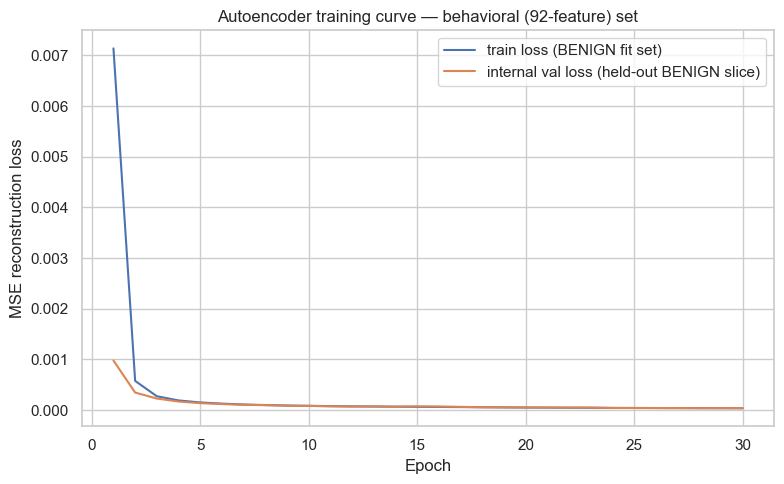

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(ae_history["train_loss"]) + 1), ae_history["train_loss"], label="train loss (BENIGN fit set)")
ax.plot(range(1, len(ae_history["val_loss"]) + 1), ae_history["val_loss"], label="internal val loss (held-out BENIGN slice)")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE reconstruction loss")
ax.set_title("Autoencoder training curve — behavioral (92-feature) set")
ax.legend()
plt.tight_layout()
plt.show()


In [21]:
X_val_full = val_df[feature_cols].to_numpy(dtype=np.float32)
reconstruction_error_behavioral = compute_reconstruction_error(ae_model_behavioral, X_val_full, DEVICE)

ae_val_scored = val_df[["Label"]].copy()
ae_val_scored["reconstruction_error"] = reconstruction_error_behavioral
ae_val_scored["is_attack"] = (ae_val_scored["Label"] != "BENIGN").astype(int)

benign_val_errors = ae_val_scored.loc[ae_val_scored["Label"] == "BENIGN", "reconstruction_error"]
auc_roc_ae_behavioral = roc_auc_score(ae_val_scored["is_attack"], ae_val_scored["reconstruction_error"])

ae_sweep_rows = []
for pct in THRESHOLD_PERCENTILES:
    threshold = float(np.percentile(benign_val_errors, pct))
    pred = (ae_val_scored["reconstruction_error"] > threshold).astype(int)
    ae_sweep_rows.append({
        "percentile": pct,
        "threshold": threshold,
        "precision": precision_score(ae_val_scored["is_attack"], pred),
        "recall": recall_score(ae_val_scored["is_attack"], pred),
        "f1": f1_score(ae_val_scored["is_attack"], pred),
        "auc_roc": auc_roc_ae_behavioral,
    })

ae_sweep_df = pd.DataFrame(ae_sweep_rows)
ae_sweep_df


,percentile,threshold,precision,recall,f1,auc_roc
0,90,0.000053,0.654118,0.930721,0.768281,0.984377
1,95,0.000113,0.789029,0.920327,0.849635,0.984377
2,99,0.000546,0.947213,0.883215,0.914095,0.984377


In [22]:
best_ae_row = ae_sweep_df.loc[ae_sweep_df["f1"].idxmax()]
AE_CHOSEN_THRESHOLD = float(best_ae_row["threshold"])
AE_CHOSEN_PERCENTILE = int(best_ae_row["percentile"])
best_ae_f1 = best_ae_row["f1"]
print(f"Chosen threshold: {AE_CHOSEN_THRESHOLD:.6f}  ({AE_CHOSEN_PERCENTILE}th percentile of val-BENIGN reconstruction error)  F1={best_ae_f1:.4f}")

prediction_ae = (ae_val_scored["reconstruction_error"] > AE_CHOSEN_THRESHOLD).astype(int)
ae_val_scored["prediction"] = prediction_ae

ae_metrics_behavioral = {
    "precision": precision_score(ae_val_scored["is_attack"], prediction_ae),
    "recall": recall_score(ae_val_scored["is_attack"], prediction_ae),
    "f1": f1_score(ae_val_scored["is_attack"], prediction_ae),
    "auc_roc": auc_roc_ae_behavioral,
}
print(f"\nBehavioral Autoencoder ({len(feature_cols)} features, val, threshold at {AE_CHOSEN_PERCENTILE}th pct):")
for k, v in ae_metrics_behavioral.items():
    print(f"  {k:10s}: {v:.4f}")


Chosen threshold: 0.000546  (99th percentile of val-BENIGN reconstruction error)  F1=0.9141

Behavioral Autoencoder (92 features, val, threshold at 99th pct):
  precision : 0.9472
  recall    : 0.8832
  f1        : 0.9141
  auc_roc   : 0.9844


In [23]:
attack_rows_ae = ae_val_scored[ae_val_scored["Label"] != "BENIGN"].copy()

ae_category_recall_behavioral = (
    attack_rows_ae.groupby("Label")
    .agg(recall=("prediction", "mean"), n_rows=("prediction", "size"))
    .sort_values("recall")
)
ae_category_recall_behavioral


,recall,n_rows
Label,,
FTP-Patator,0.000000,1186
Web Attack - Sql Injection,0.000000,4
Web Attack - XSS,0.000000,131
SSH-Patator,0.001553,644
Web Attack - Brute Force,0.003401,294
Bot,0.012821,390
DoS GoldenEye,0.470102,2057
DoS slowloris,0.610028,1077
PortScan,0.752798,18139


## 9. Before/after comparison — the key result

Two groups of categories:
- **Categories this experiment targeted** (near-0% recall on the original 80-feature set):
  FTP-Patator, SSH-Patator, PortScan, Bot.
- **Categories that already worked well** (flood-style attacks, to check for regression): DoS
  Hulk, DDoS, DoS GoldenEye. A feature addition that fixes Patator but breaks flood detection
  would be a wash, not a win.

Remember the Section 2 caveat: baseline and behavioral recall come from **different underlying
val row sets** (different raw source, different split) -- this compares aggregate recall on a
category, not matched rows.

In [24]:
WATCH_CATEGORIES = ["FTP-Patator", "SSH-Patator", "PortScan", "Bot", "DoS Hulk", "DDoS", "DoS GoldenEye"]

def build_comparison(baseline_recall_df, behavioral_recall_df, model_name):
    rows = []
    for cat in WATCH_CATEGORIES:
        baseline_r = float(baseline_recall_df.loc[cat, "recall"]) if cat in baseline_recall_df.index else float("nan")
        baseline_n = int(baseline_recall_df.loc[cat, "n_rows"]) if cat in baseline_recall_df.index else 0
        behavioral_r = float(behavioral_recall_df.loc[cat, "recall"]) if cat in behavioral_recall_df.index else float("nan")
        behavioral_n = int(behavioral_recall_df.loc[cat, "n_rows"]) if cat in behavioral_recall_df.index else 0
        rows.append({
            "model": model_name,
            "category": cat,
            "baseline_recall_80f": baseline_r,
            "baseline_n_rows": baseline_n,
            "behavioral_recall_92f": behavioral_r,
            "behavioral_n_rows": behavioral_n,
            "delta": behavioral_r - baseline_r,
        })
    return pd.DataFrame(rows)

if_comparison_df = build_comparison(baseline_if_category_recall, if_category_recall_behavioral, "IsolationForest")
ae_comparison_df = build_comparison(baseline_ae_category_recall, ae_category_recall_behavioral, "Autoencoder")

before_after_df = pd.concat([if_comparison_df, ae_comparison_df], ignore_index=True)
before_after_df


,model,category,baseline_recall_80f,baseline_n_rows,behavioral_recall_92f,behavioral_n_rows,delta
0,IsolationForest,FTP-Patator,0.000000,1186,0.000000,1186,0.000000
1,IsolationForest,SSH-Patator,0.000000,644,0.001553,644,0.001553
2,IsolationForest,PortScan,0.002371,18139,0.070456,18139,0.068085
3,IsolationForest,Bot,0.023136,389,0.012821,390,-0.010316
4,IsolationForest,DoS Hulk,0.869453,34570,0.932367,34569,0.062914
5,IsolationForest,DDoS,0.573136,25603,0.631332,25603,0.058196
6,IsolationForest,DoS GoldenEye,0.479339,2057,0.459407,2057,-0.019932
7,Autoencoder,FTP-Patator,0.000843,1186,0.000000,1186,-0.000843
8,Autoencoder,SSH-Patator,0.000000,644,0.001553,644,0.001553
9,Autoencoder,PortScan,0.002701,18139,0.752798,18139,0.750096


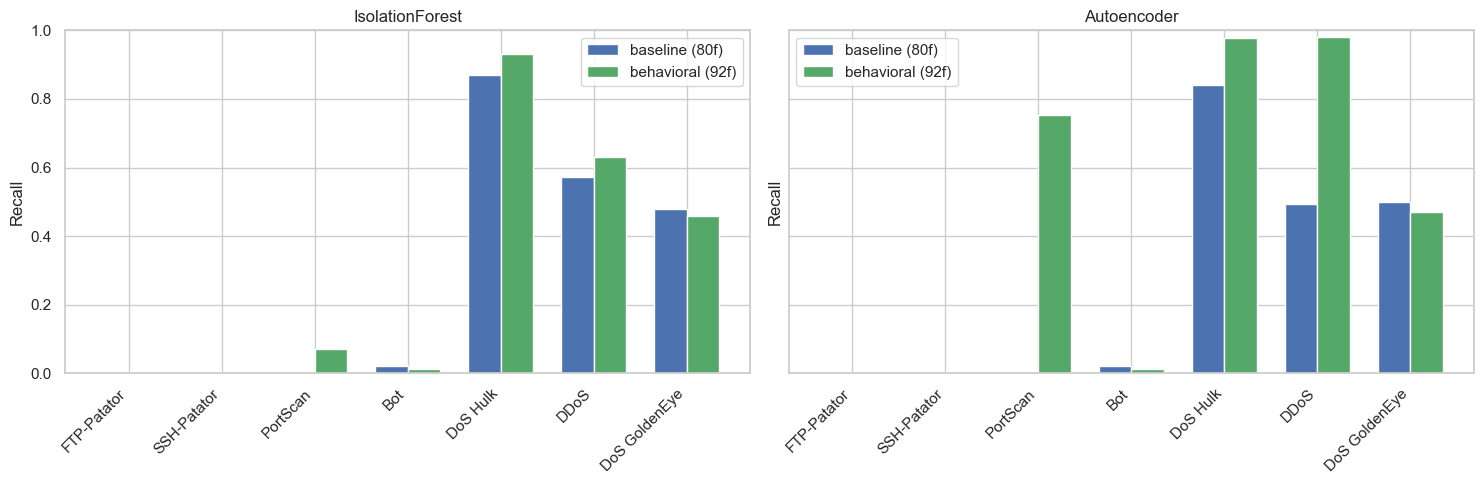

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, model_name, df_m in zip(axes, ["IsolationForest", "Autoencoder"], [if_comparison_df, ae_comparison_df]):
    x = np.arange(len(df_m))
    width = 0.35
    ax.bar(x - width/2, df_m["baseline_recall_80f"], width, label="baseline (80f)", color="#4C72B0")
    ax.bar(x + width/2, df_m["behavioral_recall_92f"], width, label="behavioral (92f)", color="#55A868")
    ax.set_xticks(x)
    ax.set_xticklabels(df_m["category"], rotation=45, ha="right")
    ax.set_title(model_name)
    ax.set_ylabel("Recall")
    ax.set_ylim(0, 1)
    ax.legend()
plt.tight_layout()
plt.show()


In [26]:
print("=== Targeted categories (were near-0% recall) ===")
targeted = before_after_df[before_after_df["category"].isin(["FTP-Patator", "SSH-Patator", "PortScan", "Bot"])]
print(targeted.to_string(index=False))

print("\n=== Already-working categories (regression check) ===")
regression_check = before_after_df[before_after_df["category"].isin(["DoS Hulk", "DDoS", "DoS GoldenEye"])]
print(regression_check.to_string(index=False))

IMPROVEMENT_THRESHOLD = 0.05
REGRESSION_THRESHOLD = -0.05

n_improved = int((targeted["delta"] > IMPROVEMENT_THRESHOLD).sum())
n_regressed = int((regression_check["delta"] < REGRESSION_THRESHOLD).sum())

print(f"\nTargeted category/model pairs improved by >{IMPROVEMENT_THRESHOLD:.0%} absolute recall: {n_improved} / {len(targeted)}")
print(f"Already-working category/model pairs regressed by >{abs(REGRESSION_THRESHOLD):.0%} absolute recall: {n_regressed} / {len(regression_check)}")


=== Targeted categories (were near-0% recall) ===
          model    category  baseline_recall_80f  baseline_n_rows  behavioral_recall_92f  behavioral_n_rows     delta
IsolationForest FTP-Patator             0.000000             1186               0.000000               1186  0.000000
IsolationForest SSH-Patator             0.000000              644               0.001553                644  0.001553
IsolationForest    PortScan             0.002371            18139               0.070456              18139  0.068085
IsolationForest         Bot             0.023136              389               0.012821                390 -0.010316
    Autoencoder FTP-Patator             0.000843             1186               0.000000               1186 -0.000843
    Autoencoder SSH-Patator             0.000000              644               0.001553                644  0.001553
    Autoencoder    PortScan             0.002701            18139               0.752798              18139  0.750096
    Au

## 10. Save results

All outputs are separately namespaced -- nothing here overwrites `models/isolation_forest.pkl`, `models/autoencoder.pt`, or any baseline report.

In [27]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

if_model_path = MODELS_DIR / "isolation_forest_behavioral.pkl"
joblib.dump(iso_forest_behavioral, if_model_path)
print("Saved:", if_model_path)

ae_model_path = MODELS_DIR / "autoencoder_behavioral.pt"
torch.save(ae_model_behavioral.state_dict(), ae_model_path)
print("Saved:", ae_model_path)

ae_config_to_save = dict(AE_CONFIG)
ae_config_to_save.update({
    "input_dim": len(feature_cols),
    "feature_cols": feature_cols,
    "chosen_threshold": AE_CHOSEN_THRESHOLD,
    "chosen_percentile": AE_CHOSEN_PERCENTILE,
    "random_state": RANDOM_STATE,
    "benign_internal_val_frac": BENIGN_INTERNAL_VAL_FRAC,
    "epochs_run": len(ae_history["train_loss"]),
    "source_dataset": "data/processed/behavioral/cicids2017_behavioral_labeled.parquet",
})
ae_config_path = MODELS_DIR / "autoencoder_behavioral_config.json"
with open(ae_config_path, "w", encoding="utf-8") as f:
    json.dump(ae_config_to_save, f, indent=2)
print("Saved:", ae_config_path)


Saved: E:\thesis\models\isolation_forest_behavioral.pkl
Saved: E:\thesis\models\autoencoder_behavioral.pt
Saved: E:\thesis\models\autoencoder_behavioral_config.json


In [28]:
val_metrics_rows = []
for model_name, metrics_dict, n_feat in [
    ("IsolationForest", if_metrics_behavioral, len(feature_cols)),
    ("Autoencoder", ae_metrics_behavioral, len(feature_cols)),
]:
    row = {"model": model_name, "feature_set": "behavioral_92f", "n_features": n_feat}
    row.update(metrics_dict)
    val_metrics_rows.append(row)

for model_name, metrics_dict, n_feat in [
    ("IsolationForest", baseline_if_metrics, 80),
    ("Autoencoder", baseline_ae_metrics, 80),
]:
    row = {"model": model_name, "feature_set": "baseline_80f", "n_features": n_feat}
    row.update(metrics_dict)
    val_metrics_rows.append(row)

enhanced_ablation_val_metrics_df = pd.DataFrame(val_metrics_rows)
val_metrics_path = REPORTS_DIR / "enhanced_ablation_val_metrics.csv"
enhanced_ablation_val_metrics_df.to_csv(val_metrics_path, index=False)
print("Saved:", val_metrics_path)
enhanced_ablation_val_metrics_df


Saved: E:\thesis\reports\enhanced_ablation_val_metrics.csv


,model,feature_set,n_features,precision,recall,f1,auc_roc
0,IsolationForest,behavioral_92f,92,0.516811,0.613050,0.560832,0.863762
1,Autoencoder,behavioral_92f,92,0.947213,0.883215,0.914095,0.984377
2,IsolationForest,baseline_80f,80,0.529191,0.555785,0.542162,0.728624
3,Autoencoder,baseline_80f,80,0.913755,0.521480,0.664010,0.864104


In [29]:
comparison_path = REPORTS_DIR / "enhanced_ablation_before_after_comparison.csv"
before_after_df.to_csv(comparison_path, index=False)
print("Saved:", comparison_path)


Saved: E:\thesis\reports\enhanced_ablation_before_after_comparison.csv


## 11. Recommendation

(Filled in from the actual run results below.)

In [30]:
print("=== SUMMARY ===")
if_delta_f1 = if_metrics_behavioral["f1"] - baseline_if_metrics["f1"]
ae_delta_f1 = ae_metrics_behavioral["f1"] - baseline_ae_metrics["f1"]
print(f"\nIsolation Forest: baseline F1={baseline_if_metrics['f1']:.4f} -> behavioral F1={if_metrics_behavioral['f1']:.4f}  (delta={if_delta_f1:+.4f})")
print(f"Autoencoder     : baseline F1={baseline_ae_metrics['f1']:.4f} -> behavioral F1={ae_metrics_behavioral['f1']:.4f}  (delta={ae_delta_f1:+.4f})")
print(f"\nTargeted categories improved (>{IMPROVEMENT_THRESHOLD:.0%} abs. recall): {n_improved} / {len(targeted)}")
print(f"Already-working categories regressed (>{abs(REGRESSION_THRESHOLD):.0%} abs. recall): {n_regressed} / {len(regression_check)}")
print("\nSee reports/enhanced_ablation_before_after_comparison.csv for the full per-category table.")


=== SUMMARY ===

Isolation Forest: baseline F1=0.5422 -> behavioral F1=0.5608  (delta=+0.0187)
Autoencoder     : baseline F1=0.6640 -> behavioral F1=0.9141  (delta=+0.2501)

Targeted categories improved (>5% abs. recall): 2 / 8
Already-working categories regressed (>5% abs. recall): 0 / 6

See reports/enhanced_ablation_before_after_comparison.csv for the full per-category table.
